In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("../data/processed/engineered_delivery.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (43739, 26)


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,...,Distance,Order_Hour,Day,Day_Of_Week,Month,Is_Weekend,Is_Peak_Hour,Distance_Traffic,Distance_Category,Rating_Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,...,3.025149,11,19,5,3,1,0,9.075448,Short,High
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,...,20.183530,19,25,4,3,0,1,80.734119,Very Long,High
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,...,1.552758,8,19,5,3,1,1,1.552758,Very Short,High
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,...,7.790401,18,5,1,4,0,1,15.580803,Medium,High
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,...,6.210138,13,26,5,3,1,0,18.630414,Medium,High


In [3]:
print(df.columns.tolist())

print(df.info())

['Order_ID', 'Agent_Age', 'Agent_Rating', 'Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude', 'Order_Date', 'Order_Time', 'Pickup_Time', 'Weather', 'Traffic', 'Vehicle', 'Area', 'Delivery_Time', 'Category', 'Distance', 'Order_Hour', 'Day', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Is_Peak_Hour', 'Distance_Traffic', 'Distance_Category', 'Rating_Category']
<class 'pandas.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           43739 non-null  str    
 1   Agent_Age          43739 non-null  int64  
 2   Agent_Rating       43739 non-null  float64
 3   Store_Latitude     43739 non-null  float64
 4   Store_Longitude    43739 non-null  float64
 5   Drop_Latitude      43739 non-null  float64
 6   Drop_Longitude     43739 non-null  float64
 7   Order_Date         43739 non-null  str    
 8   Order_Time         43739 non-null  str    


In [4]:
features = [
    "Agent_Age",
    "Agent_Rating",
    "Store_Latitude",
    "Store_Longitude",
    "Drop_Latitude",
    "Drop_Longitude",
    "Distance",
    "Order_Hour",
    "Day",
    "Day_Of_Week",
    "Month",
    "Is_Weekend",
    "Is_Peak_Hour",
    "Weather",
    "Traffic",
    "Vehicle",
    "Area",
    "Category",
    "Distance_Category",
    "Distance_Traffic",
    "Rating_Category"
]

X = df[features]

y = df["Delivery_Time"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features Shape: (43739, 21)
Target Shape: (43739,)


,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Distance,Order_Hour,Day,Day_Of_Week,...,Is_Weekend,Is_Peak_Hour,Weather,Traffic,Vehicle,Area,Category,Distance_Category,Distance_Traffic,Rating_Category
0,37,4.9,22.745049,75.892471,22.765049,75.912471,3.025149,11,19,5,...,1,0,Sunny,High,motorcycle,Urban,Clothing,Short,9.075448,High
1,34,4.5,12.913041,77.683237,13.043041,77.813237,20.183530,19,25,4,...,0,1,Stormy,Jam,scooter,Metropolitian,Electronics,Very Long,80.734119,High
2,23,4.4,12.914264,77.678400,12.924264,77.688400,1.552758,8,19,5,...,1,1,Sandstorms,Low,motorcycle,Urban,Sports,Very Short,1.552758,High
3,38,4.7,11.003669,76.976494,11.053669,77.026494,7.790401,18,5,1,...,0,1,Sunny,Medium,motorcycle,Metropolitian,Cosmetics,Medium,15.580803,High
4,32,4.6,12.972793,80.249982,13.012793,80.289982,6.210138,13,26,5,...,1,0,Cloudy,High,scooter,Metropolitian,Toys,Medium,18.630414,High


In [5]:
print("Input Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nMissing Values in X:", X.isnull().sum().sum())
print("Missing Values in y:", y.isnull().sum())


Input Features:
['Agent_Age', 'Agent_Rating', 'Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude', 'Distance', 'Order_Hour', 'Day', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Is_Peak_Hour', 'Weather', 'Traffic', 'Vehicle', 'Area', 'Category', 'Distance_Category', 'Distance_Traffic', 'Rating_Category']

Target:
Delivery_Time

Missing Values in X: 0
Missing Values in y: 0


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (34991, 21)
Testing Data: (8748, 21)
Training Target: (34991,)
Testing Target: (8748,)


In [7]:
categorical_columns = X_train.select_dtypes(include=["object"]).columns.tolist()

numerical_columns = X_train.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical Columns:", categorical_columns)

print("\nNumerical Columns:", numerical_columns)

Categorical Columns: ['Weather', 'Traffic', 'Vehicle', 'Area', 'Category', 'Distance_Category', 'Rating_Category']

Numerical Columns: ['Agent_Age', 'Agent_Rating', 'Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude', 'Distance', 'Order_Hour', 'Day', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Is_Peak_Hour', 'Distance_Traffic']


C:\Users\divya\AppData\Local\Temp\ipykernel_35140\1906116922.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(include=["object"]).columns.tolist()


In [8]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Categorical Columns:", categorical_columns)

print("\nNumerical Columns:", numerical_columns)

Categorical Columns: ['Weather', 'Traffic', 'Vehicle', 'Area', 'Category', 'Distance_Category', 'Rating_Category']

Numerical Columns: ['Agent_Age', 'Agent_Rating', 'Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude', 'Distance', 'Order_Hour', 'Day', 'Day_Of_Week', 'Month', 'Is_Weekend', 'Is_Peak_Hour', 'Distance_Traffic']


C:\Users\divya\AppData\Local\Temp\ipykernel_35140\3083152112.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

print("Training Shape:", X_train_encoded.shape)
print("Testing Shape:", X_test_encoded.shape)

Training Shape: (34991, 56)
Testing Shape: (8748, 56)


In [10]:
print("Original Training Shape:", X_train.shape)

print("Encoded Training Shape:", X_train_encoded.shape)

print("Original Testing Shape:", X_test.shape)

print("Encoded Testing Shape:", X_test_encoded.shape)

Original Training Shape: (34991, 21)
Encoded Training Shape: (34991, 56)
Original Testing Shape: (8748, 21)
Encoded Testing Shape: (8748, 56)


In [11]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_encoded, y_train)

baseline_predictions = baseline_model.predict(X_test_encoded)

print("Baseline Model Trained Successfully!")

Baseline Model Trained Successfully!


In [12]:
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model Performance")

print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

Baseline Model Performance
MAE: 41.221410216438564
RMSE: 51.61795394964311
R2 Score: -0.00017840317141692985


In [13]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_encoded, y_train)

linear_predictions = linear_model.predict(X_test_encoded)

print("Linear Regression Trained Successfully!")

Linear Regression Trained Successfully!


In [14]:
linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Performance")

print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression Performance
MAE: 24.84399610760784
RMSE: 31.290612044505334
R2 Score: 0.6324605026957111


In [15]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "RMSE": [baseline_rmse, linear_rmse],
    "R2 Score": [baseline_r2, linear_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Baseline,41.221410,51.617954,-0.000178
1,Linear Regression,24.843996,31.290612,0.632461


In [16]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_encoded, y_train)

random_forest_predictions = random_forest_model.predict(X_test_encoded)

print("Random Forest Trained Successfully!")

Random Forest Trained Successfully!


In [17]:
rf_mae = mean_absolute_error(y_test, random_forest_predictions)

rf_rmse = np.sqrt(mean_squared_error(y_test, random_forest_predictions))

rf_r2 = r2_score(y_test, random_forest_predictions)

print("Random Forest Performance")

print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Performance
MAE: 17.08462797121111
RMSE: 22.18418483854103
R2 Score: 0.8152591867160033


In [18]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Random Forest"],
    "MAE": [baseline_mae, linear_mae, rf_mae],
    "RMSE": [baseline_rmse, linear_rmse, rf_rmse],
    "R2 Score": [baseline_r2, linear_r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Baseline,41.221410,51.617954,-0.000178
1,Linear Regression,24.843996,31.290612,0.632461
2,Random Forest,17.084628,22.184185,0.815259


In [19]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": random_forest_predictions
})

results["Error"] = results["Actual"] - results["Predicted"]

results["Absolute_Error"] = abs(results["Error"])

results.head(10)

,Actual,Predicted,Error,Absolute_Error
0,145,107.329064,37.670936,37.670936
1,21,30.485478,-9.485478,9.485478
2,165,118.924664,46.075336,46.075336
3,200,173.560794,26.439206,26.439206
4,145,125.564214,19.435786,19.435786
5,180,142.821997,37.178003,37.178003
6,120,127.068462,-7.068462,7.068462
7,180,205.005496,-25.005496,25.005496
8,155,174.571668,-19.571668,19.571668
9,85,119.296254,-34.296254,34.296254


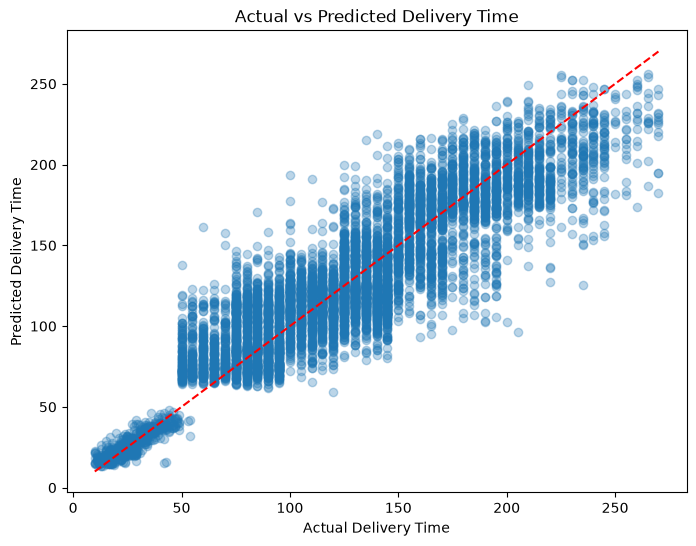

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, random_forest_predictions, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")
plt.title("Actual vs Predicted Delivery Time")

plt.show()

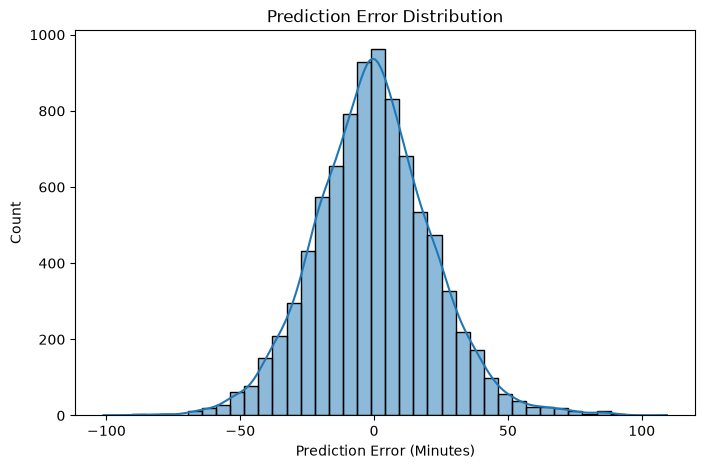

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(results["Error"], bins=40, kde=True)

plt.xlabel("Prediction Error (Minutes)")
plt.title("Prediction Error Distribution")

plt.show()

In [22]:
within_10_minutes = (results["Absolute_Error"] <= 10).mean() * 100

print("Predictions Within 10 Minutes:", round(within_10_minutes, 2), "%")

Predictions Within 10 Minutes: 38.37 %


In [23]:
print("Mean Error:", results["Error"].mean())

print("Mean Absolute Error:", results["Absolute_Error"].mean())

print("Maximum Error:", results["Absolute_Error"].max())

print("Minimum Error:", results["Absolute_Error"].min())

print("Predictions Within 5 Minutes:", (results["Absolute_Error"] <= 5).mean() * 100)

print("Predictions Within 15 Minutes:", (results["Absolute_Error"] <= 15).mean() * 100)

Mean Error: -0.1478300984898599
Mean Absolute Error: 17.08462797121111
Maximum Error: 109.43888227513224
Minimum Error: 0.002798587817650855
Predictions Within 5 Minutes: 20.679012345679013
Predictions Within 15 Minutes: 53.37219935985368


In [24]:
results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

,Actual,Predicted,Error,Absolute_Error
6547,235,125.561118,109.438882,109.438882
1281,205,96.645770,108.354230,108.354230
767,60,161.141994,-101.141994,101.141994
2227,200,102.346389,97.653611,97.653611
1625,100,193.478388,-93.478388,93.478388
4132,220,127.531581,92.468419,92.468419
1301,195,105.559868,89.440132,89.440132
1657,245,155.705402,89.294598,89.294598
6401,70,157.738333,-87.738333,87.738333
310,50,137.725820,-87.725820,87.725820


In [25]:
feature_names = preprocessor.get_feature_names_out()

importance = random_forest_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
23,cat__Category_Grocery,0.243538
43,remainder__Agent_Rating,0.170678
55,remainder__Distance_Traffic,0.161494
42,remainder__Agent_Age,0.088590
4,cat__Weather_Sunny,0.061814
1,cat__Weather_Fog,0.036194
0,cat__Weather_Cloudy,0.035702
48,remainder__Distance,0.030251
11,cat__Vehicle_motorcycle,0.024341
8,cat__Traffic_Low,0.019628


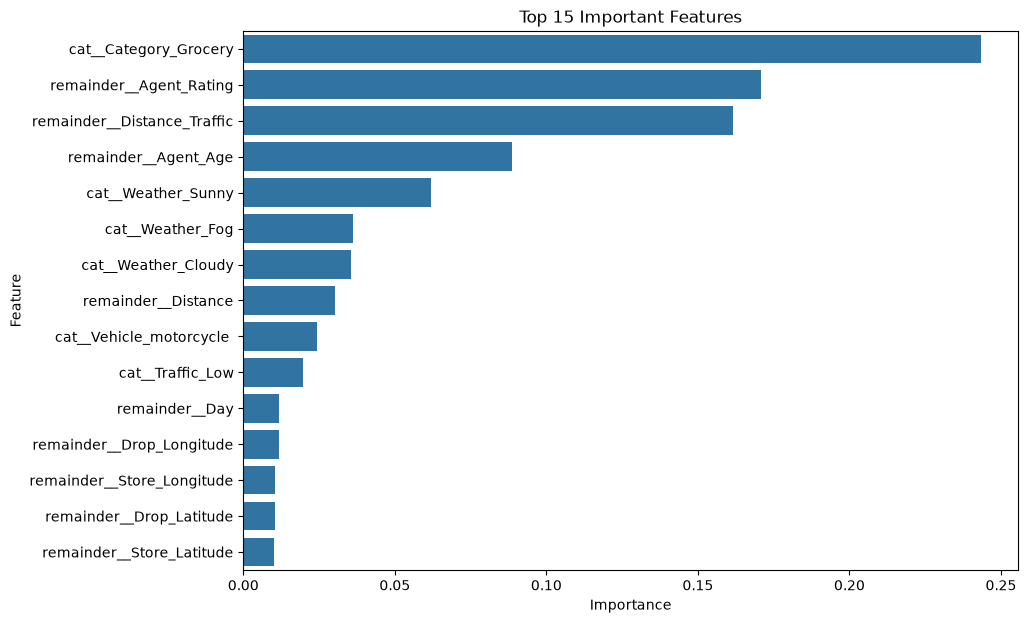

In [26]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [27]:
print("Top 10 Important Features")

print(feature_importance.head(10))

Top 10 Important Features
                        Feature  Importance
23        cat__Category_Grocery    0.243538
43      remainder__Agent_Rating    0.170678
55  remainder__Distance_Traffic    0.161494
42         remainder__Agent_Age    0.088590
4            cat__Weather_Sunny    0.061814
1              cat__Weather_Fog    0.036194
0           cat__Weather_Cloudy    0.035702
48          remainder__Distance    0.030251
11     cat__Vehicle_motorcycle     0.024341
8              cat__Traffic_Low    0.019628


In [29]:
within_10_minutes = (results["Absolute_Error"] <= 10).mean() * 100
print("Predictions Within 10 Minutes:", round(within_10_minutes, 2), "%")

Predictions Within 10 Minutes: 38.37 %


In [30]:
print("Mean Error:", results["Error"].mean())

print("Mean Absolute Error:", results["Absolute_Error"].mean())

print("Maximum Error:", results["Absolute_Error"].max())

print("Predictions Within 5 Minutes:", (results["Absolute_Error"] <= 5).mean() * 100)

print("Predictions Within 15 Minutes:", (results["Absolute_Error"] <= 15).mean() * 100)

Mean Error: -0.1478300984898599
Mean Absolute Error: 17.08462797121111
Maximum Error: 109.43888227513224
Predictions Within 5 Minutes: 20.679012345679013
Predictions Within 15 Minutes: 53.37219935985368


In [31]:
results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

,Actual,Predicted,Error,Absolute_Error
6547,235,125.561118,109.438882,109.438882
1281,205,96.645770,108.354230,108.354230
767,60,161.141994,-101.141994,101.141994
2227,200,102.346389,97.653611,97.653611
1625,100,193.478388,-93.478388,93.478388
4132,220,127.531581,92.468419,92.468419
1301,195,105.559868,89.440132,89.440132
1657,245,155.705402,89.294598,89.294598
6401,70,157.738333,-87.738333,87.738333
310,50,137.725820,-87.725820,87.725820


In [32]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(random_forest_model, "../models/random_forest_model.pkl")

joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [33]:
print(os.listdir("../models"))

['preprocessor.pkl', 'random_forest_model.pkl']
